In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten

In [6]:
train=pd.read_csv("C:/Users/Dell/Deep_Learning_practicals/sign_mnist_train.csv")
test=pd.read_csv("C:/Users/Dell/Deep_Learning_practicals/sign_mnist_test.csv")

print("Training shape:", train.shape)
print("Testing shape:", test.shape)

Training shape: (27455, 785)
Testing shape: (7172, 785)


In [7]:
X_train = train.drop("label", axis=1)
y_train = train["label"]

X_test = test.drop("label", axis=1)
y_test = test["label"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

X_train: (27455, 784)
X_test: (7172, 784)


In [8]:
X_train = X_train / 255.0
X_test = X_test / 255.0

print("Pixel values normalized")

Pixel values normalized


In [9]:
#cell same for 1,2,3,5and13
model = Sequential([
    Flatten(input_shape=(784,)),
    Dense(128, activation="relu"),
    Dense(25, activation="softmax")
])

model.summary()


C:\Users\Dell\anaconda3\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         100,480 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 25)                  │           3,225 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 103,705 (405.10 KB)

 Trainable params: 103,705 (405.10 KB)

 Non-trainable params: 0 (0.00 B)

In [10]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [11]:
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=128,
    validation_split=0.1
)

Epoch 1/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 15s 38ms/step - accuracy: 0.2945 - loss: 2.5226 - val_accuracy: 0.4446 - val_loss: 1.9291
Epoch 2/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 6s 30ms/step - accuracy: 0.5365 - loss: 1.6640 - val_accuracy: 0.6122 - val_loss: 1.4510
Epoch 3/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.6492 - loss: 1.2903 - val_accuracy: 0.6923 - val_loss: 1.1583
Epoch 4/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7013 - loss: 1.0850 - val_accuracy: 0.6835 - val_loss: 1.0344
Epoch 5/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - accuracy: 0.7510 - loss: 0.9280 - val_accuracy: 0.6919 - val_loss: 0.9136
Epoch 6/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.7789 - loss: 0.8222 - val_accuracy: 0.8081 - val_loss: 0.7401
Epoch 7/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 6s 28ms/step - accuracy: 0.8030 - loss: 0.7342 - val_accuracy: 0.7906 - val_loss: 0.7215
Epoch 8/10
194/194 ━━━━━━━━━━━━━━━━━━━━ 5s 27ms/step - accuracy: 0.8288 - loss: 0.6521 - val_acc

In [13]:
#output for 1
loss, accuracy = model.evaluate(X_test, y_test)

print("Test Accuracy:", accuracy)
print("Test Accuracy (%):", accuracy * 100)

225/225 ━━━━━━━━━━━━━━━━━━━━ 3s 14ms/step - accuracy: 0.6825 - loss: 1.0737
Test Accuracy: 0.6825153231620789
Test Accuracy (%): 68.25153231620789


In [14]:
#change cell 7 for PS 2
history = model.fit(
    X_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_data=(X_test, y_test)
)

Epoch 1/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.8442 - loss: 0.5234 - val_accuracy: 0.6845 - val_loss: 1.0449
Epoch 2/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.8971 - loss: 0.3735 - val_accuracy: 0.7078 - val_loss: 1.0091
Epoch 3/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9175 - loss: 0.3042 - val_accuracy: 0.6871 - val_loss: 1.0479
Epoch 4/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.9375 - loss: 0.2433 - val_accuracy: 0.7094 - val_loss: 1.0877
Epoch 5/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 18s 21ms/step - accuracy: 0.9550 - loss: 0.1905 - val_accuracy: 0.7057 - val_loss: 1.0418
Epoch 6/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 17s 20ms/step - accuracy: 0.9643 - loss: 0.1573 - val_accuracy: 0.7119 - val_loss: 1.1088
Epoch 7/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 19s 22ms/step - accuracy: 0.9698 - loss: 0.1333 - val_accuracy: 0.6640 - val_loss: 1.3939
Epoch 8/10
858/858 ━━━━━━━━━━━━━━━━━━━━ 20s 23ms/step - accuracy: 0.9801 - loss: 0.1028 - 

In [15]:
#cell for chit 2
print("Training Accuracy:",
      history.history["accuracy"][-1])

print("Testing Accuracy:",
      history.history["val_accuracy"][-1])

Training Accuracy: 0.9854671359062195
Testing Accuracy: 0.7229503393173218


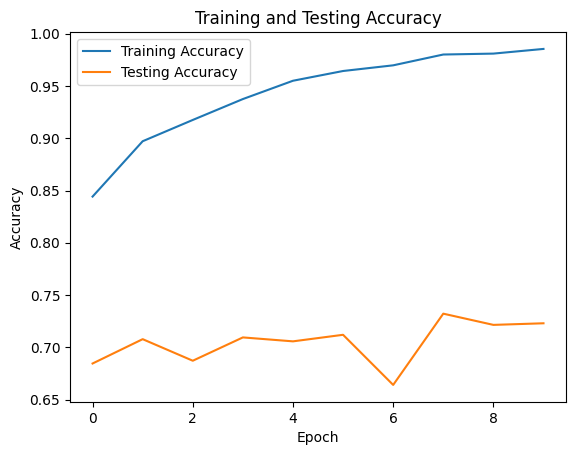

In [16]:
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Testing Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training and Testing Accuracy")

plt.legend()
plt.show()

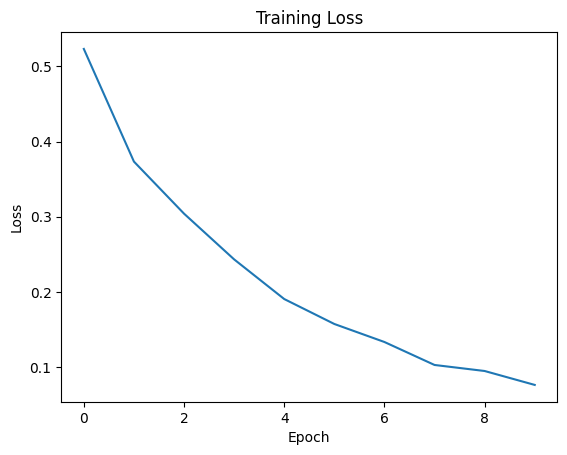

In [17]:
plt.plot(history.history["loss"])

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")

plt.show()

In [18]:
#For chit 3
#cell 1-6 same cell 7
#model.fit(X_train, y_train,epochs=10,batch_size=32)

225/225 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step


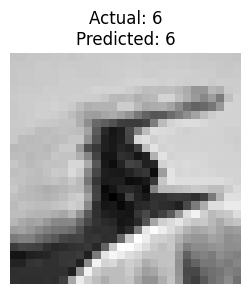

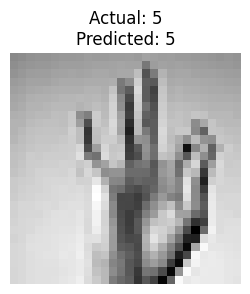

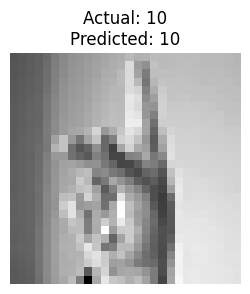

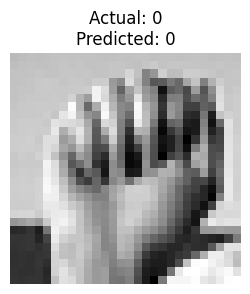

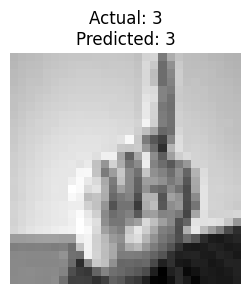

In [19]:
#for chit 3 cell 8
predictions = model.predict(X_test)

for i in range(5):

    actual = y_test.iloc[i]
    predicted = np.argmax(predictions[i])

    plt.figure(figsize=(3, 3))

    plt.imshow(
        X_test.iloc[i].values.reshape(28, 28),
        cmap="gray"
    )

    plt.title(
        f"Actual: {actual}\nPredicted: {predicted}"
    )

    plt.axis("off")
    plt.show()

In [ ]:
#for ps 5 cell 8 update
y_pred = np.argmax(
    model.predict(X_test),
    axis=1
)

print("Predictions completed")

In [ ]:
#for chit 5 
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

In [ ]:
#confusion matrix
plt.figure(figsize=(10, 8))

plt.imshow(cm)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix")

plt.colorbar()
plt.show()

In [ ]:
#Chit13 is same as 2